<a href="https://colab.research.google.com/github/LucioFassarella/SQC/blob/main/SQC_state-preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# State preparation and expectation value via computational simulation

 Hilbert space of a single qubit and its computational basis
 $$
 \mathcal{H} = \mathbb{C}^2 = \text{spam} \left\{\vert 0 \rangle,\vert 1 \rangle \right\}.
$$
The initialization state and the mixed state to prepair:

$$
\vert \psi_0 \rangle := \vert 0 \rangle \in \mathcal{H}
$$
and
$$
\begin{split}
	\rho &= \frac{2}{3}\vert + \rangle \langle + \vert + \frac{1}{3}\vert + \rangle \langle - \vert,
\end{split}
$$
where we have the ortonormal vectors
$$
 \vert \psi_1 \rangle:= \vert + \rangle = \frac{\vert 0 \rangle + \vert 1 \rangle}{\sqrt{2}}\ \text{e}\  \vert \psi_2 \rangle:= \vert - \rangle=\frac{\vert 0 \rangle - \vert 1 \rangle}{\sqrt{2}}.
$$
Unitaries
$$
U_1 := H \equiv \frac{1}{\sqrt{2}}%
\begin{pmatrix}
	1 & 1\\
	1 & -1
\end{pmatrix}\ %
\ \text{e}\ \ %
U_2 := HX \equiv \frac{1}{\sqrt{2}}%
\begin{pmatrix}
	1 & 1\\
	-1 & 1
\end{pmatrix},
$$
satisfying
$$
U_k \vert \psi_0 \rangle = \vert \psi_k \rangle,\ k = 1,2.
$$
Kraus operators and the associated quantum channel:
$$
E_1 =  \sqrt{2/3}H\ \ \text{e}\ \ E_2 = \sqrt{1/3}HX
$$
and
$$
\mathcal{E}_\rho: \mathcal{L} (\mathcal{H})\rightarrow  \mathcal{L} (\mathcal{H}),\ \mathcal{E}_\rho  [\Gamma] := E_1 \Gamma E_1^\dagger + E_2 \Gamma E_2^\dagger =\frac{2}{3}H\Gamma H + \frac{1}{3}HX\Gamma XH.
$$
Auxiliar Hilbert space Stinespring dilation for $\mathcal{E}_\rho$:
$$
\mathcal{G} = \mathbb{C}^2 \equiv \mathrm{spam} { \vert u_0 \rangle:= \vert 0 \rangle, \vert u_1 \rangle:=\vert 1 \rangle};
$$
and
$$
V_\rho: \mathcal{H}\rightarrow \mathcal{H}\otimes \mathcal{G},\ %
V_\rho \vert \psi \rangle:=  (E_1 \vert \psi \rangle) \otimes \vert 0 \rangle +  (E_2  \vert \psi \rangle) \otimes \vert 1 \rangle%
= H \vert \psi \rangle \otimes \vert 0 \rangle + HX \vert \psi \rangle \otimes \vert 1 \rangle.
$$
Auxiliar principal vector and Stinespring unitary corresponding to the pair $ (V_\rho, \vert u_0 \rangle)$:
$$
 \vert u_0 \rangle:= \sqrt{\frac{2}{3}}\vert 0 \rangle + \sqrt{\frac{1}{3}}\vert 1 \rangle = R_y (2\arctan(1/\sqrt{2})),\ %
R_y(\theta) = \begin{pmatrix}
	\cos(\frac{\theta}{2}) & -\sin(\frac{\theta}{2})\\
	\sin(\frac{\theta}{2}) & \cos(\frac{\theta}{2})
\end{pmatrix};
$$
and
$$
W_\rho  ( \vert \psi_\ell \rangle\otimes  \vert u_k \rangle) =  (U_k \vert \psi_\ell \rangle)\otimes  \vert k \rangle %
= HX_C^{1\rightarrow 0} ( \vert \ell \rangle\otimes  \vert k \rangle)%
= \left\{
\begin{array}{rl}
	H \vert \ell \rangle \otimes \vert 0 \rangle,& k = 0\ (\ell = 0,1);\\
	HX \vert \ell \rangle \otimes \vert 1 \rangle,& k = 1\ (\ell = 0,1).
\end{array}
\right.
$$
 where $X_C^{0\rightarrow 1}$ meand the controled $X$ gate, having the right qubit (auxiliar) as control and the left qubit (principal) as target.\\

Obervable
$$
A = X - Y + 2Z
$$
The expected value of $H$ with respect to the state $\rho$ is given by
$$
\langle H \rangle_\rho = tr \left(\rho (X - Y + 2Z)\right) = tr(\rho X) - tr(\rho Y) + 2^2tr (\rho Z)= \frac{1}{3\sqrt{2}}.
$$



# Qiskit installation

In [1]:
'''
Qiskit installation
'''

!pip install qiskit -U
!pip install qiskit_aer -U
!pip install qiskit-ibm-runtime -U

import qiskit
qiskit.__version__

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 74.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 41.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 32.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 41.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 15.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [qiskit-ibm-runtime]


'2.6.1'

In [2]:
'''
Tools for visualization
'''

!pip install matplotlib
!pip install pylatexenc

# Texlive installation to print the quantum circuit in LaTeX format
!apt-get update && apt-get install -y texlive-latex-extra texlive-pictures poppler-utils

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cli.github.com/packages stable/main amd64 Packages [356 B]
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:7 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,086 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.4 MB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.0 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,549 kB

# Simulation

Quantum Circuit


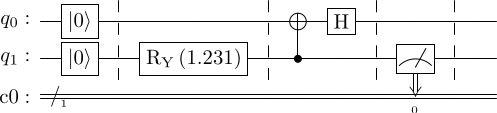

'\\documentclass[border=2px]{standalone}\n\n\\usepackage[braket, qm]{qcircuit}\n\\usepackage{graphicx}\n\n\\begin{document}\n\\scalebox{1.0}{\n\\Qcircuit @C=1.0em @R=0.2em @!R { \\\\\n\t \t\\nghost{{q}_{0} :  } & \\lstick{{q}_{0} :  } & \\gate{\\mathrm{\\left|0\\right\\rangle}} \\barrier[0em]{1} & \\qw & \\qw \\barrier[0em]{1} & \\qw & \\targ & \\gate{\\mathrm{H}} \\barrier[0em]{1} & \\qw & \\qw \\barrier[0em]{1} & \\qw & \\qw & \\qw\\\\\n\t \t\\nghost{{q}_{1} :  } & \\lstick{{q}_{1} :  } & \\gate{\\mathrm{\\left|0\\right\\rangle}} & \\qw & \\gate{\\mathrm{R_Y}\\,(\\mathrm{1.231})} & \\qw & \\ctrl{-1} & \\qw & \\qw & \\meter & \\qw & \\qw & \\qw\\\\\n\t \t\\nghost{\\mathrm{{c0} :  }} & \\lstick{\\mathrm{{c0} :  }} & \\lstick{/_{_{1}}} \\cw & \\cw & \\cw & \\cw & \\cw & \\cw & \\cw & \\dstick{_{_{\\hspace{0.0em}0}}} \\cw \\ar @{<=} [-1,0] & \\cw & \\cw & \\cw\\\\\n\\\\ }}\n\\end{document}'

In [3]:
'''
Quantum circuit to prepare the state \rho
'''

# Methods

import numpy as np

from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.quantum_info import Operator
from qiskit_aer import AerSimulator

# Quantum circuit and registers
qr = QuantumRegister(2, name="q")
cr = ClassicalRegister(1)
qc = QuantumCircuit(qr, cr)

# Initialization
qc.reset(qr[0])
qc.reset(qr[1])
qc.barrier()
theta = 2*np.arctan(np.sqrt(1/2))
qc.ry(theta, qr[1])
qc.barrier()

# Stinespring's unitary
qc.cx(qr[1],qr[0])
qc.h(qr[0])

qc.barrier()

# Partial measurement and qubit recycling
qc.measure(qr[1], cr[0])
qc.barrier()

# Draw the circuit
print("Quantum Circuit")
display(qc.draw(output='latex'))
display(qc.draw(output='latex_source'))

In [ ]:
# Saving the circuit's figure
fig = qc.draw(output='mpl')

# Save the figure to a file (e.g., PNG, PDF, or SVG)
fig.savefig('SQO_StatePreparation.png', bbox_inches='tight', dpi=300)

print("Circuit diagram saved: 'SQO_StatePreparation.png'!")

Circuit diagram saved successfully as 'SQO_StatePreparation.png'!


In [ ]:
'''
Expectation value of the observable H with respect to the state \rho
'''

# Methods
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import Estimator as AerEstimator

# Observable
observable = SparsePauliOp.from_list([("II", 1), ("IX", 2), ("IY", -3), ("IZ",4)])

# AerEstimator
shots = 10**6  # precision = 1/sqrt(shots)
estimator = Estimator(run_options={"shots": shots})
job = estimator.run(qc, observable)
result = job.result()

# Result
exp_val = result.values[0]
print(f"Observable: {observable}")
print(f"Expectation Value (using Estimator): {exp_val:.6f}")

Observable: SparsePauliOp(['II', 'IX', 'IY', 'IZ'],
              coeffs=[ 1.+0.j,  2.+0.j, -3.+0.j,  4.+0.j])
Expectation Value (using Estimator): 1.668124
